# 1 Molecular dynamics

## Describing a set of interacting particles

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 1.3 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

## 1.3 Multiple particles

For $N$ identical particles in two dimensions, $\quad \displaystyle \frac{d\mathbf v_i}{dt}= \sum_{j\ne i}\frac{\mathbf F_{ij}}{m} \quad$. 

(Textbook, Eq. 1.10). 


<a id="lj-1"></a>
### Test case: The Lennard-Jones gas

We reproduce an ensemble of particles interacting via the Lennard-Jones potential, which is a well-known model for atom-atom interactions in physics.

The Lennard–Jones pair potential (Eq. 1.11) is

$$V(r)=4\,\epsilon\,\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6 \right].$$

The force on particle $i$ (located in $\mathbf r_i$) due to particle $j$ (located in $\mathbf r_j$) is:

$$\mathbf F_{ij}=24\,\frac{\epsilon}{r}\,\left[2 \left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6 \right]\,\hat{\mathbf r}_{ij}$$ 

with $\mathbf r_{ij}=\mathbf r_i-\mathbf r_j$ and $r = |r_{ij}|$.

We use reduced units $\quad m = \sigma = \epsilon =1, \quad$ so time is measured in $\quad \displaystyle \tau = \sigma{\sqrt{\frac{m}{2 \epsilon}}} \quad$. 

(textbook Exercise 1.6)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Let's plot the Lennard-Jones potential

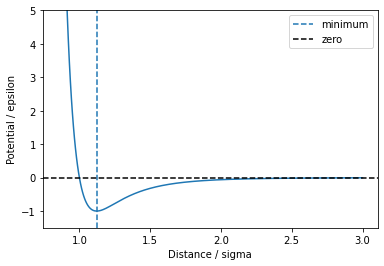

In [2]:
# plotting the Lennard-Jones potential

rmin = 0.85
rmax = 3.0
rnum = 300

distance = np.linspace(rmin, rmax, rnum)
energy = 4 * (distance ** -12 - distance ** -6)  

plt.plot(distance, energy); 
plt.ylim(-1.5, 5)
plt.axvline(2**(1/6), linestyle="--", label="minimum")
plt.axhline(0, linestyle="--", color="k", label="zero")
plt.xlabel("Distance / sigma"); 
plt.ylabel("Potential / epsilon"); 
plt.legend(); 
plt.show()

Let's plot the force.

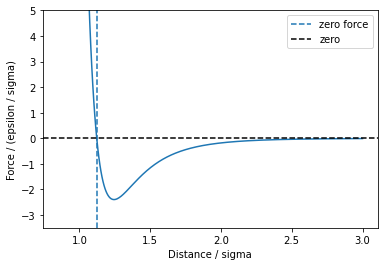

In [3]:
# plotting the Lennard-Jones force

force = 24 * (2 * distance ** -12 - distance ** -6) / distance

plt.plot(distance, force); 
plt.ylim(-3.5, 5)
plt.axvline(2**(1/6), linestyle="--", label="zero force")
plt.axhline(0, linestyle="--", color="k", label="zero")
plt.xlabel("Distance / sigma"); 
plt.ylabel("Force / (epsilon / sigma)"); 
plt.legend(); 
plt.show()

<a id="3-particles"></a>
### A simple start: the case of three particles

We start with three non-overlapping particles interacting with Lennard-Jones potential. 

We calculate the forces on each particle and we verify that Newton's third law is valid: we check that the *total internal force* must vanish.

In [4]:
# manually set the positions

pos1 = [1.0, 1.0]
pos2 = [2.5, 1.0]
pos3 = [1.5, 2.5]

positions = np.array([pos1, pos2, pos3])
forces = np.zeros_like(positions)

for i in range(len(positions)):
    for j in range(i + 1, len(positions)):
        displacement = positions[i] - positions[j]
        squared_distance = np.dot(displacement, displacement)
        inverse_sixth = squared_distance**-3
        pair_force = 24 * (
            2 * inverse_sixth**2 - inverse_sixth
        ) * displacement / squared_distance
        forces[i] += pair_force
        forces[j] -= pair_force
        
print(forces, "\n\nNet internal force:", forces.sum(axis=0))

[[ 1.42590723  0.8036352 ]
 [-1.36061427  0.30387816]
 [-0.06529296 -1.10751336]] 

Net internal force: [1.66533454e-16 0.00000000e+00]


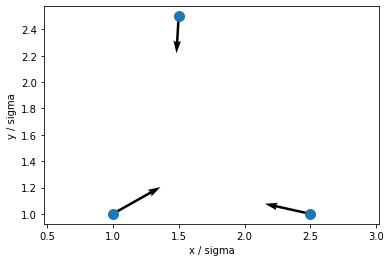

In [5]:
# plot in xy
plt.plot(positions[:, 0], positions[:, 1], ".", markersize=20)

# plot forces
plt.quiver(
    positions[:, 0], positions[:, 1],
    forces[:, 0], forces[:, 1],
    scale=10
)

plt.axis("equal")
plt.xlabel("x / sigma")
plt.ylabel("y / sigma")
plt.show()

<a id="2d-gas-1"></a>
### Exercise 1.6: Two dimensional gas in a box 

The following cells use the same pair-force loop, now for a small gas. 

We reject positions that are too close and use randomly oriented velocities without a fixed seed. 

Walls reflect the normal velocity component. A wall can exchange momentum with the gas, so total particle momentum need not be conserved.

In [6]:
rng = np.random.default_rng()

N = 16  
print(f"Number of particles: {N}")

box_length = 12
print(f"Box dimension: {box_length} sigma")

positions = []
while len(positions) < N:
    candidate = rng.uniform(1, box_length - 1, 2)
    if all(np.linalg.norm(candidate - p) > 1.0 for p in positions):
        positions.append(candidate)
positions = np.array(positions)

Number of particles: 16
Box dimension: 12 sigma


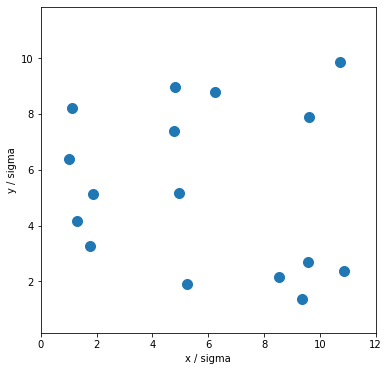

In [7]:
# plot in xy
plt.figure(figsize=(6, 6))
plt.plot(positions[:, 0], positions[:, 1], ".", markersize=20)

plt.axis("equal")
plt.xlim([0, box_length])
plt.ylim([0, box_length])
plt.xlabel("x / sigma")
plt.ylabel("y / sigma")
plt.show()

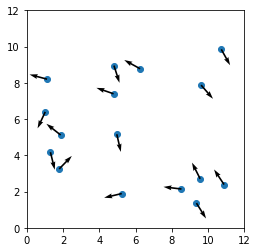

In [8]:
# generate random velocities

angles = rng.uniform(0, 2 * np.pi, N)
velocities = np.column_stack((np.cos(angles), np.sin(angles)))

plt.scatter(positions[:, 0], positions[:, 1]); 
# plot forces
plt.quiver(
    positions[:, 0], positions[:, 1],
    velocities[:, 0], velocities[:, 1],
    scale_units="xy", scale=1
)

plt.xlim(0, box_length); 
plt.ylim(0, box_length); 
plt.gca().set_aspect("equal"); 
plt.show()

Here we let the system evolve, using leapfrog method.

In [9]:
# set time step, number of steps

dt = 0.0005
print(f"Time step: {dt} tau")

nsteps = 1000
print(f"Number of time steps: {nsteps}")

for step in range(nsteps):
    midpoint = positions + 0.5 * dt * velocities
    forces = np.zeros_like(midpoint)
    for i in range(N):
        for j in range(i + 1, N):
            displacement = midpoint[i] - midpoint[j]
            r2 = np.dot(displacement, displacement)
            inv6 = r2 ** -3
            pair = 24 * (2 * inv6 ** 2 - inv6) * displacement / r2
            forces[i] += pair
            forces[j] -= pair
    velocities += dt * forces
    positions = midpoint + 0.5 * dt * velocities
    for axis in range(2):
        low = positions[:, axis] < 0
        positions[low, axis] *= -1 
        velocities[low, axis] *= -1
        high = positions[:, axis] > box_length
        positions[high, axis] = (
            2 * box_length - positions[high, axis]
        )
        velocities[high, axis] *= -1
    

Time step: 0.0005 tau
Number of time steps: 1000


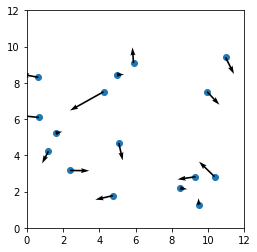

In [10]:
# replot after iterations

# plot positions
plt.scatter(positions[:, 0], positions[:, 1]); 
# plot velocities
plt.quiver(
    positions[:, 0], positions[:, 1],
    velocities[:, 0], velocities[:, 1],
    scale_units="xy", scale=1
)

plt.xlim(0, box_length); 
plt.ylim(0, box_length); 
plt.gca().set_aspect("equal"); 
plt.show()

<a id="vectorization"></a>
### Using vectorization in the module

The notebook loop processes one pair at a time. 

The [module "molecular_dynamics.py"](../01_modules/molecular_dynamics.py) computes the same $N\times N$ displacement array with NumPy broadcasting and sums force contributions. 

Both still have $O(N^2)$ cost and require avoiding overlapping particles. 

See textbook Section 1.5 for cell lists and Verlet lists. 

The module omits force cutoffs to avoid introducing another approximation.

See the code in the module.

In [11]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().parent / "01_modules"))

import molecular_dynamics as md

From the former positions, we calculate the force with
```python
md.lennard_jones_force
```

In [12]:
# calculate the forces and the total force

module_forces = md.lennard_jones_force(positions)

print("Net force from module:", module_forces.sum(axis=0))

Net force from module: [1.33226763e-15 2.22044605e-15]


Let's start anew: 
1. we generate a Lennard-Jones gas, with **initial_gas**
2. we let the system evolve for a cetrain time interval, with **step_particles**
3. and we monitor its kinetic energy, potential energy, and total energy, with **kinetic_energy**, **potential_energy**


In [13]:
N = 36
box_length = 15.0
nsteps = 1000
dt = 0.001
nskip = 10  # number of steps between two energy calculations

positions, velocities = md.initial_gas(N, box_length)
energies = []
for step in range(nsteps):
    positions, velocities = md.step_particles(
        positions, velocities, dt, box_length)
    if step % nskip == 0:
        kinetic = md.kinetic_energy(velocities)
        potential = md.potential_energy(positions)
        energies.append([kinetic, potential, kinetic + potential])

<a id="energies"></a>Now I plot the kinetic, potential, and total energy

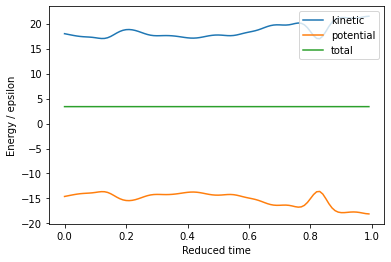

In [14]:
energies = np.asarray(energies)
for i, label in enumerate(("kinetic", "potential", "total")):
    plt.plot(
        np.arange(len(energies)) * nskip * dt, 
        energies[:, i], 
        label=label
    )
plt.xlabel("Reduced time")
plt.ylabel("Energy / epsilon")
plt.legend()
plt.show()

<div style="background-color:#f0f8ff; border: 2px solid #4682b4; padding: 10px;">

 **Think:** Which energies fluctuate? How does total-energy drift change with timestep? A reflected wall preserves speed at collision, but position corrections can perturb pair potential energy; what does this imply for interpreting the plot?
    
</div>

### Live pygame view (local and Colab-compatible fallback)

Pygame draws the *current* simulation state. 

Locally, an SDL window can be used; in hosted notebooks, a pygame `Surface` can be converted to an inline frame. 

This cell chooses inline display by default so it does not require a desktop display. 

Install pygame if missing (`%pip install pygame`). 

The live output is a sequence of rendered frames, not a precomputed GIF. 

The display route requires testing on actual Colab and local machines before it is declared verified.

In [15]:
try:
    import pygame
except ImportError:
    %pip -q install pygame
    import pygame
    
# io and ipywidgets needed to avoid flickering on certain browsers
import io
import ipywidgets as widgets

# needed for animation
from IPython.display import display
from PIL import Image

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [16]:
N = 25
box_length = 12.0
nsteps = 10000
dt = 0.001
nskip = 10  # number of steps between two energy calculations

# parameters for pygame
window_size = 360
scale = window_size / box_length
color_p = (35, 110, 185)
color_bg = (250, 250, 250)
particle_radius = round(0.5 * scale)

image_widget = widgets.Image(
    format="png", width=window_size, height=window_size)
label = widgets.Label(value="Step: 0")
display(widgets.VBox([label, image_widget]))
# display(image_widget)

positions, velocities = md.initial_gas(N, box_length)
pygame.init()

surface = pygame.Surface((window_size, window_size))

for frame in range(nsteps // nskip):
    for step in range(nskip):
        positions, velocities = md.step_particles(
            positions, velocities, dt, box_length
        )
    surface.fill(color_bg)
    for x, y in positions:
        pygame.draw.circle(
            surface, 
            color_p, 
            (int(x * scale), int(y * scale)), 
            particle_radius
        )
    label.value = f"Step: {(frame + 1) * nskip}"
    pixels = pygame.surfarray.array3d(surface).swapaxes(0, 1)
    
    buffer = io.BytesIO()
    Image.fromarray(pixels).save(buffer, format="PNG")
    image_widget.value = buffer.getvalue()
pygame.quit()

Let's add arrows representing the velocity of each particle

In [17]:
N = 25
box_length = 12.0
nsteps = 10000
dt = 0.001
nskip = 10  # number of steps between two energy calculations

# parameters for pygame
window_size = 360
scale = window_size / box_length
color_p = (35, 110, 185)
color_bg = (250, 250, 250)
particle_radius = round(0.5 * scale)
color_v = (50, 50, 50)  # dark grey arrows
velocity_scale = round(1.0 * scale)

image_widget = widgets.Image(
    format="png", width=window_size, height=window_size)
label = widgets.Label(value="Step: 0")
display(widgets.VBox([label, image_widget]))
# display(image_widget)

positions, velocities = md.initial_gas(N, box_length)
pygame.init()

surface = pygame.Surface((window_size, window_size))

for frame in range(nsteps // nskip):
    for step in range(nskip):
        positions, velocities = md.step_particles(
            positions, velocities, dt, box_length)
    surface.fill(color_bg)
    for (x, y), (vx, vy) in zip(positions, velocities):
        center = np.array([x, y]) * scale
        tip = center + np.array([vx, vy]) * velocity_scale
        # draw particle
        pygame.draw.circle(
            surface, color_p, center.astype(int), particle_radius)      
        # Draw velocity arrow
        pygame.draw.line(surface, color_v, center, tip, width=2)
        # Draw arrowhead
        direction = tip - center
        length = np.linalg.norm(direction)
        if length > 0:
            unit = direction / length
            perpendicular = np.array([-unit[1], unit[0]])
            head_length = min(8, length * 0.4)
            head_width = head_length * 0.5
            left = (tip - head_length * unit 
                    + head_width * perpendicular)
            right = (tip - head_length * unit 
                     - head_width * perpendicular)
            pygame.draw.polygon(surface, color_v, 
                                [tip, left, right])
    label.value = f"Step: {(frame + 1) * nskip}"
    pixels = pygame.surfarray.array3d(surface).swapaxes(0, 1)
    
    buffer = io.BytesIO()
    Image.fromarray(pixels).save(buffer, format="PNG")
    image_widget.value = buffer.getvalue()
pygame.quit()

<a id="questions"></a>
## Questions

Here you find the questions:
    
* [Q7: Lennard-Jones force and potential](#q7)
    
* [Q8: module: lennard_jones_forces](#q8)
    
* [Q9: module: initial_gas](#q9)
    
* [Q10: module: step_particles](#q10)
    
* [Q11: module: kinetic_energy and potential_energy](#q11)
   

<a id="q7"></a>**Question 7:** Lennard-Jones force and potential.

Refer to [Lennard-Jones](#lj-1), [the case of three particles](#3-particles), [2 dimensional gas in a box]("2d-gas-1") 
(parts before vectorization)

[Go back to questions](#questions)

a. What does $\sigma$ represent in the Lennard-Jones potential and force equation?


b. Why must we prevent nearly overlapping (i.e., closer than $\sigma$) initial particles?
 

c. Show that the Lennard-Jones force on particle $i$ due to particle $j$ is equal and opposite to the Lennard-Jones force on particle $j$ due to particle $i$, i.e., $\mathbf F_{ij} = - \mathbf F_{ji}$


d. Show that the sum of all the internal forces in a Lennard-Jones system is equal to zero: $\sum_{i} \sum_{j\ne i} \mathbf F_{ij} = 0$


e. In [the case of three particles](#3-particles), amend the plot of the three particles so that circles of radius $\sigma / 2$ are drawn around each point particle. Write the code.


f. Do any of the three circles intersect with one another? 


g. Change the position of particle 2 so that the interaction with particle 1 is repulsive. Verify with the code.


h. Arrange the three particles so that the force on each particle is exactly zero. How can you do this? Verify with the code.


i. What is the initial speed of the particles in reduced units, in the [2 dimensional gas in a box]("2d-gas-1") 
(parts before vectorization)?
  
    
j. Modify the code to generate a set of random velocities with uniform speed equal to 2 (in reduced units).


k. Modify the code to include the calculation of the total internal force in each time step. Verify to which extent it is zero.
    

l. Modify the code to retain the initial position for each particle.


m. Modify the code to plot, for each particle, the initial position, the final position, and an arrow going from the initial position to the respective final position.



<a id="q8"></a>**Question 8:** *lennard_jones_force* in the module.

Refer to [using vectorization in the module](#vectorization)
and check the [module molecular_dynamics.py](../01_modules/molecular_dynamics.py)

[Go back to questions](#questions)

In *lennard_jones_force* : assume positions.shape is (N, d)


a. What is the shape of:
```python 
positions[:, None, :]
displacement 
squared 
inv6
coefficient
coefficient[..., None]
ljf
```

b. Explain the effect of "None" in the following lines:
```python 
positions[:, None, :]
coefficient[..., None]
```

c. Explain the meaning of "..." in the following line:    
```python 
coefficient[..., None]    
```
    

<a id="q9"></a>**Question 9:** *initial_gas* in the module.

Refer to [using vectorization in the module](#vectorization)
and check the [module molecular_dynamics.py](../01_modules/molecular_dynamics.py) 

[Go back to questions](#questions)

a. What is the meaning of "\_" in the line
```python 
for _ in range(N):
```


b. Does the following belong to the "if"? Why or why not?
```python   
else:
            raise ValueError('Box too crowded for requested separation')
```

c. What are the following variables:
```python   
candidate
old
velocities
```

d. What does the function return?
```python   
return np.array(positions), velocities
```

e. In the script, I have:
```python   
positions, velocities = md.initial_gas(N, box_length)
```
What is the output of the following lines:
```python   
type(positions)
type(velocities)
```

<a id="q10"></a>**Question 10:** *step_particles* in the module.

Refer to [using vectorization in the module](#vectorization)
and check the [module molecular_dynamics.py](../01_modules/molecular_dynamics.py) 

[Go back to questions](#questions)

Assume positions.shape is (N, d)

a. What is the shape of each of the following:
```python 
midpoint
forces 
mass_array 
mass_array[:, None]
acceleration
velocities
```

b. Assume masses = 1.0 . What is the shape of mass_array?
```python    
mass_array = np.broadcast_to(masses, (len(positions),))
```


c. Assume masses = \[24, 12, 3, 1, 3, 2\]  and  len(positions) is 7 .
Is mass_array assigned correctly? Why or why not?
```python    
mass_array = np.broadcast_to(masses, (len(positions),))
```

<a id="q11"></a>**Question 11:** *kinetic_energy* and *potential_energy* in the module.

Refer to [using vectorization in the module](#vectorization)
and check the [module molecular_dynamics.py](../01_modules/molecular_dynamics.py) 

Refer to the [plot of the energies](#energies) after the vectorization.

[Go back to questions](#questions)

a. What is the output of the following line
```python    
type(KE)
```
where KE = md.kinetic_energy(velocities) ?


In *potential_energy* : assume positions.shape is (N, d)

b. What is the shape of:
```python 
displacement 
squared
pairs
```

c. If len(positions) = 3, write the output of:
```python 
np.triu_indices(len(positions), 1)
```


d. What is the output of the following line
```python    
type(PE)
```
where PE = md.potential_energy(positions) ?


e. Adjust the code to plot the total energy *only*. Do you see fluctuations? 
  
    
f. Quantify the numerical fluctuation of the total energy. Does it change with the time step $dt$? 
    
    
g. How do the *numerical* fluctuations of the total energy compare with the *intrinsic* fluctuations in the kinetic and potential energy?
